# 13 — External references: how do other CPUs and GPUs do on the same model?

**Objective.** Place our measurements (Xeon CPU Max 9480, one socket, HBM cache mode) next to published results for the same
model, Llama-3.1-8B, so that later work starts from a calibrated view: where we are far off, where we are close, and which
metric (throughput, time to first token, time per output token, energy) separates the systems most.

**Research questions.**
1. How do our BF16 and INT8 throughputs compare with other CPUs (Xeon 6, Arm) and with GPUs (L40S, H100, H200, B200)?
2. Where is the gap smallest: throughput, TTFT, TPOT or energy per token?
3. How much of each system's memory bandwidth does single-stream decode use (ours against the GPUs')?

**Data.**
- `data/external/reference_results.csv`: one row per published measurement, built by
  `scripts/processing/build_external_references.py` from the sources in `data/external/sources.csv`. Machine-readable
  sources (ML.ENERGY leaderboard, NVIDIA NIM tables, MLPerf v5.1 summaries) are parsed. The rest (Lenovo LP2463, Arm, Red
  Hat) are transcribed in `manual_results.csv`, and Lenovo's values are digitised from its figures.
- Our points come from the primary online campaign (`online_points.csv`, 8B) and from the campaign `external-shapes`
  (2026-10-18, jobs 5404538–39), which re-measured vLLM BF16 at exactly two published shapes and concurrencies: NVIDIA NIM
  1000→1000 at C = 1, 5, 25, 50, 100, 128 and Lenovo LP2463 256→256 at C = 1…128 (`configs/experiment.toml`
  `[external_shapes]`, same layout and repetitions as the primary campaign).
- The model is **Llama-3.1-8B-Instruct**. Llama-3.2-1B is our cross-check model, but no BF16 serving results for it were
  found online, and we do not use Llama-3.2-3B.

**How to read the ratios.** Every external row is paired with our nearest point. The pairing uses the same precision
class, the nearest workload shape that configuration was measured at (log distance of ISL and OSL; the external-match
shapes included) and the nearest concurrency of that sweep. For MLPerf, which
reports throughput only, it uses our peak over the sweep. All ratios are *external advantage* factors: > 1 means the
external system is better. For throughput that is external ÷ ours; for TTFT, TPOT and energy it is ours ÷ external. The
vLLM configuration of each precision class (the selected backend) is the reference, and llama.cpp is reported alongside.
Grades: **A** = same model, precision, shape and C; **B** = same model and precision class, other shape; **C** = loosely
comparable.

**Our energy is measured at the node, not at the socket.** RAPL is not readable on CRESCO8 (see `docs/methodology.md`), but
Slurm records the node's energy through IPMI (DCMI sensor: both sockets, memory and platform, updated every 60 s). The
external-shapes runs read it at the start and end of every repetition, which gives an average node power per point. A point
measured over at least 10 minutes uses its own power. Every other point, including the primary campaign, uses
`POWER_W`, the median of those measured powers. Our J/token is power ÷ output tok/s. The node boundary includes the idle
second socket, the client and the platform, so it is an upper bound on the server's own energy. It replaces the earlier
placeholder, the 350 W TDP of one socket.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import external
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "13_external_references.ipynb"
keys = pd.read_csv(paths.TABLES / "backend_selection" / "key_numbers.csv").set_index("key")
STREAM_GBS = float(keys.loc["roof_memory_in_hbm_cache_gbs", "low"])

refs = external.references()
points = loaders.online_points(model=registry.primary_model())
ext_points = loaders.online_points(campaign=external.MEASURED_CAMPAIGN, model=registry.primary_model())
POWERS = external.measured_power_w(ext_points)   # node power of the points with a window of at least 10 minutes
POWER_W = float(POWERS.median()) if len(POWERS) else external.POWER_W_ASSUMED
IDLE = external.idle_power(loaders.node_idle_power())   # idle node, same IPMI sensor (campaign kind `power`)
IDLE_W = float(IDLE["idle_power_w"].median()) if len(IDLE) else np.nan
comp = external.compare(refs, pd.concat([points, ext_points], ignore_index=True), power_w=POWER_W, idle_power_w=IDLE_W)
src = external.sources()
KEYS = []


def key(name, values, fmt, description):
    v = pd.Series(values, dtype=float).dropna()
    KEYS.append({"key": name, "text": rng(v, fmt) if len(v) else "–", "low": v.min(), "high": v.max(), "n": len(v),
                 "description": description})


def ratio(v):
    return x(v, 2) if v < 10 else x(v, 1)

## 1. Sources and how comparable they are

In [2]:
cnt = comp.groupby(["source_id", "grade"]).size().unstack(fill_value=0).reindex(columns=["A", "B", "C"], fill_value=0)
s = src.set_index("source_id")[["title", "publisher", "kind", "accessed"]].join(cnt).reset_index()
display(table(s.rename(columns={"source_id": "Source", "title": "Document", "publisher": "Publisher", "kind": "Kind", "accessed": "Accessed",
                                "A": "Grade A rows", "B": "Grade B rows", "C": "Grade C rows"}), align="left"))
g = comp["grade"].value_counts()
show(f"{len(refs)} published measurements from {refs['source_id'].nunique()} sources: {int(g.get('A', 0))} of grade A, {int(g.get('B', 0))} of grade B, "
     f"{int(g.get('C', 0))} of grade C. No source runs one of our primary shapes, so two published sweeps were re-measured at their exact shape. "
     f"The grade A rows are NIM's BF16 1000→1000 sweep at C = {', '.join(str(int(v)) for v in sorted(comp.loc[comp['grade'] == 'A', 'concurrency'].unique()))} "
     f"({', '.join(h.removeprefix('NVIDIA ') for h in comp.loc[comp['grade'] == 'A', 'hardware'].unique())}). NIM's C = 150–250 lie beyond our C = 128. "
     f"Lenovo's 256→256 rows now share our shape and C, but stay grade B because its Table 2 names the model as Meta Llama 3 8B (same architecture; Llama 3.1-8B in its text).")

Source,Document,Publisher,Kind,Accessed,Grade A rows,Grade B rows,Grade C rows
mlenergy_v3,"The ML.ENERGY Leaderboard v3.0, task LM Arena chat (leaderboard data file)",ML.ENERGY Initiative (University of Michigan),independent,2026-10-18,0,0,20
nvidia_nim,"NVIDIA NIM LLM Benchmarking 1.0.0, Performance (Llama-3.1-8b-instruct results)",NVIDIA,vendor,2026-10-18,15,161,39
mlperf_v51_intel,"MLPerf Inference v5.1 Datacenter (closed), Intel 1-node-2S-GNR_128C, llama3_1-8b",MLCommons / Intel,audited,2026-10-18,0,0,2
mlperf_v51_lenovo,"MLPerf Inference v5.1 Datacenter (closed), Lenovo ThinkSystem SR650 V4 GNR 86C, llama3_1-8b",MLCommons / Lenovo,audited,2026-10-18,0,0,2
redhat_mlperf_v51,Efficient and reproducible LLM inference: Red Hat MLPerf Inference v5.1 results,Red Hat,vendor,2026-10-18,0,0,4
lenovo_lp2463,"Power-Efficient LLM Inference with Intel Xeon 6 Processors (LP2463, E. Page, 2 July 2026)",Lenovo Press,vendor,2026-10-18,0,21,0
arm_vllm_quant,Arm Learning Path: Benchmark Llama throughput (vLLM BF16 vs INT8 W8A8),Arm,vendor,2026-10-18,0,0,2


266 published measurements from 7 sources: 15 of grade A, 182 of grade B, 69 of grade C. No source runs one of our primary shapes, so two published sweeps were re-measured at their exact shape. The grade A rows are NIM's BF16 1000→1000 sweep at C = 1, 5, 25, 50, 100 (H100 SXM 80GB, H200 SXM 141GB, L40S 48GB (PCIe)). NIM's C = 150–250 lie beyond our C = 128. Lenovo's 256→256 rows now share our shape and C, but stay grade B because its Table 2 names the model as Meta Llama 3 8B (same architecture; Llama 3.1-8B in its text).

**Kinds of source.** *Audited* means MLPerf, reviewed by the other submitters. *Independent* means the academic ML.ENERGY
benchmark. *Vendor* means the documentation or white papers of NVIDIA, Lenovo, Arm and Red Hat. Vendor numbers are
best-case configurations of their own products.

## 2. Other CPUs

### 2.1 BF16: Xeon 6 with vLLM (Lenovo LP2463) and Arm with vLLM

Lenovo runs the same engine family as us (vLLM CPU 0.21, BF16) on three Xeon 6 SKUs at 256→256, from 1 to 128 users. We
re-measured that shape at its concurrencies (campaign `external-shapes`, vLLM BF16 only, so no llama.cpp column for these
rows). The paper does not say whether one or both sockets of its dual-socket servers served the model,
so the comparison is per system, not per socket. Its values are digitised from Figures 1–2. Aggregate tok/s is per-user
tok/s × users.

In [3]:
cpu_bf16 = comp[(comp["hardware_class"] == "cpu") & (comp["precision_group"] == "bf16")]
cols = {"hardware": "System", "workload": "Shape", "concurrency": "C", "output_tok_s": "External tok/s", "ttft_s": "External TTFT (s)",
        "our_workload": "Our shape", "our_concurrency": "Our C", "ours_output_tok_s": "vLLM BF16 tok/s", "ours_ttft_s": "vLLM BF16 TTFT (s)",
        "other_output_tok_s": "llama.cpp BF16 tok/s", "adv_throughput": "Throughput ext ÷ ours", "adv_ttft": "TTFT ours ÷ ext", "grade": "Grade"}
display(table(cpu_bf16.assign(our_workload=cpu_bf16["our_workload"].map(lambda w: registry.workload_label(w, short=True)))[list(cols)].rename(columns=cols),
              {"C": "{:.0f}", "External tok/s": "{:.1f}", "External TTFT (s)": "{:.2f}", "Our C": "{:.0f}", "vLLM BF16 tok/s": "{:.1f}",
               "vLLM BF16 TTFT (s)": "{:.2f}", "llama.cpp BF16 tok/s": "{:.1f}", "Throughput ext ÷ ours": "{:.2f}×", "TTFT ours ÷ ext": "{:.2f}×"}, align="left"))
le = cpu_bf16[cpu_bf16["source_id"] == "lenovo_lp2463"]
by = {h: g for h, g in le.groupby("hardware")}
c1 = le[le["concurrency"] == 1].set_index("hardware")
arm = cpu_bf16[cpu_bf16["source_id"] == "arm_vllm_quant"].iloc[0]
show(f"**Throughput.** Against vLLM BF16 at the same shape and C, the 96-core Xeon 6972P delivers {rng(by['Intel Xeon 6972P']['adv_throughput'], ratio)} our output tok/s "
     f"and the 72-core 6960P {rng(by['Intel Xeon 6960P']['adv_throughput'], ratio)}. The 32-core 6732P delivers {rng(by['Intel Xeon 6732P']['adv_throughput'], ratio)}, "
     f"so our 55-core Xeon Max socket sits between the 32-core and the 72/96-core Xeon 6 parts. "
     f"Single stream (C = 1): {num(c1.loc['Intel Xeon 6972P', 'output_tok_s'], 1)} and {num(c1.loc['Intel Xeon 6960P', 'output_tok_s'], 1)} tok/s for the 96- and 72-core SKUs "
     f"against our {num(c1['ours_output_tok_s'].iloc[0], 1)} (vLLM BF16, 256→256). Our scaling flattens between C = 64 and 128 "
     f"({num(le.query('concurrency == 64')['ours_output_tok_s'].iloc[0])} and {num(le.query('concurrency == 128')['ours_output_tok_s'].iloc[0])} tok/s), "
     f"while the Xeon 6 parts still gain {rng(le.query('concurrency == 128').set_index('hardware')['output_tok_s'] / le.query('concurrency == 64').set_index('hardware')['output_tok_s'] - 1, lambda v: pct(v, 0))}.")
le8 = le[le["concurrency"] >= 8]
show(f"**TTFT.** From C = 8 upward our median TTFT is {rng(le8['adv_ttft'], ratio)} Lenovo's (ours ÷ external), so ours is lower. At C = 4 it is "
     f"{rng(le[le['concurrency'] == 4]['adv_ttft'], ratio)} (ours higher where both are a few hundred milliseconds or less). The prompts are now the same length, "
     f"so the difference is the engines' scheduling and queueing, not the shape. "
     f"Arm (96 Neoverse cores, vLLM BF16, ShareGPT at request rate 8, max concurrency {int(arm['concurrency'])}) reaches {num(arm['output_tok_s'], 1)} output tok/s, "
     f"{ratio(arm['adv_throughput'])} of our vLLM BF16 at C = {int(arm['our_concurrency'])} on {registry.workload_label(arm['our_workload'], short=True)} (grade C: other dataset and arrival process).")
key("ext_cpu_bf16_xeon6_96c_over_ours", by["Intel Xeon 6972P"]["adv_throughput"], ratio, "Xeon 6972P (96 cores, vLLM BF16, 256→256) output tok/s ÷ ours (vLLM BF16, 256→256, external-shapes), same C = 1…128 (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_72c_over_ours", by["Intel Xeon 6960P"]["adv_throughput"], ratio, "Xeon 6960P (72 cores) output tok/s ÷ ours, same shape 256→256 and C (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_32c_over_ours", by["Intel Xeon 6732P"]["adv_throughput"], ratio, "Xeon 6732P (32 cores) output tok/s ÷ ours, same shape 256→256 and C (Lenovo LP2463, digitised)")
key("ext_cpu_bf16_xeon6_ttft_ours_over_ext", le8["adv_ttft"], ratio, "Our TTFT ÷ Lenovo's Xeon 6 TTFT, same shape 256→256 and C = 8…128 (< 1: ours lower)")

System,Shape,C,External tok/s,External TTFT (s),Our shape,Our C,vLLM BF16 tok/s,vLLM BF16 TTFT (s),llama.cpp BF16 tok/s,Throughput ext ÷ ours,TTFT ours ÷ ext,Grade
"Arm Neoverse server, 96 cores (128-bit SVE, 192 GB)",ShareGPT (256 prompts),10,64.3,0.61,256→256,8,129.9,0.24,–,0.49×,0.40×,C
Intel Xeon 6732P,256→256,1,15.2,–,256→256,1,18.2,0.18,–,0.83×,–,B
Intel Xeon 6732P,256→256,4,54.5,–,256→256,4,70.3,0.24,–,0.77×,–,B
Intel Xeon 6732P,256→256,8,100.5,0.74,256→256,8,129.9,0.24,–,0.77×,0.33×,B
Intel Xeon 6732P,256→256,16,187.4,1.39,256→256,16,233.9,0.25,–,0.80×,0.18×,B
Intel Xeon 6732P,256→256,32,320.3,2.37,256→256,32,364.3,0.27,–,0.88×,0.11×,B
Intel Xeon 6732P,256→256,64,423.7,3.46,256→256,64,523.4,0.36,–,0.81×,0.10×,B
Intel Xeon 6732P,256→256,128,531.2,4.81,256→256,128,534.6,1.92,–,0.99×,0.40×,B
Intel Xeon 6960P,256→256,1,28.8,–,256→256,1,18.2,0.18,–,1.58×,–,B
Intel Xeon 6960P,256→256,4,100.2,–,256→256,4,70.3,0.24,–,1.43×,–,B


**Throughput.** Against vLLM BF16 at the same shape and C, the 96-core Xeon 6972P delivers 1.49×–1.96× our output tok/s and the 72-core 6960P 1.43×–1.60×. The 32-core 6732P delivers 0.77×–0.99×, so our 55-core Xeon Max socket sits between the 32-core and the 72/96-core Xeon 6 parts. Single stream (C = 1): 28.4 and 28.8 tok/s for the 96- and 72-core SKUs against our 18.2 (vLLM BF16, 256→256). Our scaling flattens between C = 64 and 128 (523 and 535 tok/s), while the Xeon 6 parts still gain +13%–+25%.

**TTFT.** From C = 8 upward our median TTFT is 0.10×–0.96× Lenovo's (ours ÷ external), so ours is lower. At C = 4 it is 2.48× (ours higher where both are a few hundred milliseconds or less). The prompts are now the same length, so the difference is the engines' scheduling and queueing, not the shape. Arm (96 Neoverse cores, vLLM BF16, ShareGPT at request rate 8, max concurrency 10) reaches 64.3 output tok/s, 0.49× of our vLLM BF16 at C = 8 on 256→256 (grade C: other dataset and arrival process).

### 2.2 8-bit: Arm (W8A8) and the CPU-only MLPerf v5.1 submissions

The MLPerf rows are dual-socket Granite Rapids servers on CNN-DailyMail summarisation: 778 input and 73 output tokens on
average, Offline and Server scenarios. Intel's submission declares INT4 weights with INT8 activations; Lenovo's declares
INT8/INT8. The shape has no counterpart among ours, so they are compared on *total* (prompt + output) tokens/s per socket
against our peak total tokens/s on the nearest shape (4096→128, vLLM W8A8). This is context, not a ratio to rely on.

In [4]:
cpu8 = comp[(comp["hardware_class"] == "cpu") & (comp["precision_group"] != "bf16")]
cols = {"source_id": "Source", "hardware": "System", "precision": "Precision", "scenario": "Scenario", "devices": "Sockets", "output_tok_s": "External output tok/s",
        "ext_total_tok_s": "External total tok/s", "our_workload": "Our shape", "our_basis": "Our point", "ours_output_tok_s": "vLLM W8A8 output tok/s",
        "ours_total_tok_s": "vLLM W8A8 total tok/s", "adv_throughput": "Output ext ÷ ours", "adv_total_throughput_per_device": "Total per socket ext ÷ ours", "grade": "Grade"}
display(table(cpu8.assign(our_workload=cpu8["our_workload"].map(lambda w: registry.workload_label(w, short=True)))[list(cols)].rename(columns=cols),
              {"Sockets": "{:.0f}", "External output tok/s": "{:.1f}", "External total tok/s": "{:.0f}", "vLLM W8A8 output tok/s": "{:.1f}",
               "vLLM W8A8 total tok/s": "{:.0f}", "Output ext ÷ ours": "{:.2f}×", "Total per socket ext ÷ ours": "{:.2f}×"}, align="left"))
mp = cpu8[cpu8["source_id"].str.startswith("mlperf")]
arm8 = cpu8[cpu8["source_id"] == "arm_vllm_quant"].iloc[0]
show(f"Per socket, the MLPerf CPU systems process {rng(mp[mp['scenario'] == 'mlperf_offline']['adv_total_throughput_per_device'], ratio)} our peak total tokens/s in Offline "
     f"(unconstrained batching) and {rng(mp[mp['scenario'] == 'mlperf_server']['adv_total_throughput_per_device'], ratio)} in Server (TTFT and TPOT limits). "
     f"Arm with W8A8 reaches {num(arm8['output_tok_s'], 1)} output tok/s at max concurrency {int(arm8['concurrency'])}, "
     f"{ratio(arm8['adv_throughput'])} of our vLLM W8A8 at C = {int(arm8['our_concurrency'])}.")
key("ext_mlperf_cpu_offline_total_per_socket_over_ours", mp[mp["scenario"] == "mlperf_offline"]["adv_total_throughput_per_device"], ratio,
    "MLPerf v5.1 CPU-only (2× Xeon 6980P W4A8; 2× Xeon 6787P W8A8) Offline total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128")
key("ext_mlperf_cpu_server_total_per_socket_over_ours", mp[mp["scenario"] == "mlperf_server"]["adv_total_throughput_per_device"], ratio,
    "MLPerf v5.1 CPU-only Server total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128")

Source,System,Precision,Scenario,Sockets,External output tok/s,External total tok/s,Our shape,Our point,vLLM W8A8 output tok/s,vLLM W8A8 total tok/s,Output ext ÷ ours,Total per socket ext ÷ ours,Grade
arm_vllm_quant,"Arm Neoverse server, 96 cores (128-bit SVE, 192 GB)",w8a8,request_rate,1,138.4,396,128→512,nearest C,721.2,895,0.19×,0.44×,C
mlperf_v51_intel,Intel Xeon 6980P,w4a8,mlperf_offline,2,1232.9,14372,4096→128,peak over C,103.6,2553,11.90×,2.81×,C
mlperf_v51_intel,Intel Xeon 6980P,w4a8,mlperf_server,2,450.8,5256,4096→128,peak over C,103.6,2553,4.35×,1.03×,C
mlperf_v51_lenovo,Intel Xeon 6787P,w8a8,mlperf_offline,2,776.9,9056,4096→128,peak over C,103.6,2553,7.50×,1.77×,C
mlperf_v51_lenovo,Intel Xeon 6787P,w8a8,mlperf_server,2,275.8,3215,4096→128,peak over C,103.6,2553,2.66×,0.63×,C


Per socket, the MLPerf CPU systems process 1.77×–2.81× our peak total tokens/s in Offline (unconstrained batching) and 0.63×–1.03× in Server (TTFT and TPOT limits). Arm with W8A8 reaches 138.4 output tok/s at max concurrency 24, 0.19× of our vLLM W8A8 at C = 32.

## 3. GPUs

### 3.1 BF16: NVIDIA NIM (L40S, H100, H200) and ML.ENERGY (H100, B200)

NIM gives closed-loop sweeps at fixed shapes. Only 1000→1000 is published in BF16, and we re-measured it at C = 1, 5, 25,
50, 100 and 128 (campaign `external-shapes`): these pairs are grade A, and NIM's C = 150–250 are set against our C = 128.
Their TTFT and ITL are means, ours are medians of per-repetition medians. ML.ENERGY runs vLLM 0.11.1 on LM Arena chat prompts with
the maximum batch size swept. Its prompt lengths are not published, so its rows are matched on output length only (grade C).

In [5]:
gpu = comp[comp["hardware_class"] == "gpu"]
nim_bf16 = gpu[(gpu["source_id"] == "nvidia_nim") & (gpu["precision"] == "bf16")]
summ = (nim_bf16.groupby("hardware", sort=False)
        .apply(lambda g: pd.Series({"C": f"{int(g['concurrency'].min())}–{int(g['concurrency'].max())}",
                                    "tok/s ext ÷ ours": rng(g["adv_throughput"], ratio),
                                    "TPOT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_tpot"].iloc[0]),
                                    "TTFT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_ttft"].iloc[0]),
                                    "TTFT ours ÷ ext, C=50": ratio(g.loc[g["concurrency"] == 50, "adv_ttft"].iloc[0]),
                                    "TTFT ours ÷ ext, C≥100": rng(g.loc[g["concurrency"] >= 100, "adv_ttft"], ratio),
                                    "peak ext tok/s": num(g["output_tok_s"].max()), "our peak tok/s": num(g["ours_output_tok_s"].max())}), include_groups=False)
        .reset_index().rename(columns={"hardware": "GPU (NIM, BF16, 1000→1000) vs vLLM BF16 1000→1000"}))
display(table(summ, align="left"))
h = {k: g for k, g in nim_bf16.groupby("hardware")}
BW = external.hardware_specs().set_index("hardware")["peak_mem_bw_gbs"]
show(f"**Throughput.** One H100 delivers {rng(h['NVIDIA H100 SXM 80GB']['adv_throughput'], ratio)} our vLLM BF16 output tok/s over the sweep, an H200 "
     f"{rng(h['NVIDIA H200 SXM 141GB']['adv_throughput'], ratio)}, an L40S {rng(h['NVIDIA L40S 48GB (PCIe)']['adv_throughput'], ratio)}. "
     f"The gap widens at high C because the GPUs keep scaling past our C = 128 plateau (above 128 the ratio is to our highest C). "
     f"**Single-stream decode** (TPOT at C = 1) is {ratio(h['NVIDIA H100 SXM 80GB'].query('concurrency == 1')['adv_tpot'].iloc[0])} faster on the H100 and "
     f"{ratio(h['NVIDIA L40S 48GB (PCIe)'].query('concurrency == 1')['adv_tpot'].iloc[0])} on the L40S. Their peak memory bandwidths are "
     f"{ratio(BW['NVIDIA H100 SXM 80GB'] / STREAM_GBS)} and {ratio(BW['NVIDIA L40S 48GB (PCIe)'] / STREAM_GBS)} our measured roof, so most of the decode gap is bandwidth (section 5).")
hh = nim_bf16[nim_bf16["hardware"].isin(["NVIDIA H100 SXM 80GB", "NVIDIA H200 SXM 141GB"])]
hi = hh[hh["concurrency"].between(100, 200)]
mid = hh[hh["concurrency"] == 50]
sat = nim_bf16[nim_bf16["adv_ttft"] < 0.5]
sat_txt = ", ".join(f"{hw.removeprefix('NVIDIA ')} at C ≥ {int(c)}" for hw, c in sat.groupby("hardware")["concurrency"].min().items())
show(f"**TTFT is where we are closest.** At the same 1000-token prompts, the H100 and H200 prefill {rng(hh[hh['concurrency'] <= 5]['adv_ttft'], ratio)} faster at C ≤ 5, "
     f"but the gap closes with load: {rng(mid['adv_ttft'], ratio)} at C = 50 and {rng(hi['adv_ttft'], ratio)} at C = 100–200, where queueing dominates both. Where a GPU saturates "
     f"({sat_txt}), "
     f"its queueing makes TTFT longer than ours (ours ÷ external down to {ratio(sat['adv_ttft'].min())}). "
     f"At C = 1 the GPUs prefill {rng(nim_bf16[nim_bf16['concurrency'] == 1]['adv_ttft'], ratio)} faster.")
key("ext_gpu_bf16_h100_over_ours", h["NVIDIA H100 SXM 80GB"]["adv_throughput"], ratio, "NIM H100 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000 (external-shapes), same C ≤ 100, our C = 128 above")
key("ext_gpu_bf16_h200_over_ours", h["NVIDIA H200 SXM 141GB"]["adv_throughput"], ratio, "NIM H200 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000, same C ≤ 100, our C = 128 above")
key("ext_gpu_bf16_l40s_over_ours", h["NVIDIA L40S 48GB (PCIe)"]["adv_throughput"], ratio, "NIM L40S BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000, same C ≤ 100, our C = 128 above")
key("ext_gpu_bf16_tpot_c1_over_ours", nim_bf16[nim_bf16["concurrency"] == 1]["adv_tpot"], ratio, "Our C=1 median TPOT ÷ NIM mean ITL (L40S, H100, H200; BF16 1000→1000, same shape)")
key("ext_gpu_bf16_ttft_high_c", hi["adv_ttft"], ratio, "Our median TTFT ÷ NIM mean TTFT, H100 and H200 BF16 1000→1000 at C = 100…200 (our C = 128 above 100)")
key("ext_gpu_bf16_ttft_c50", mid["adv_ttft"], ratio, "Our median TTFT ÷ NIM mean TTFT, H100 and H200 BF16 1000→1000 at C = 50 (grade A)")

"GPU (NIM, BF16, 1000→1000) vs vLLM BF16 1000→1000",C,tok/s ext ÷ ours,"TPOT ours ÷ ext, C=1","TTFT ours ÷ ext, C=1","TTFT ours ÷ ext, C=50","TTFT ours ÷ ext, C≥100",peak ext tok/s,our peak tok/s
NVIDIA H100 SXM 80GB,1–250,8.37×–19.8×,8.69×,30.0×,1.70×,0.23×–1.22×,"7,435",404
NVIDIA H200 SXM 141GB,1–250,8.04×–23.5×,7.96×,28.5×,1.36×,0.62×–1.16×,"8,813",404
NVIDIA L40S 48GB (PCIe),1–200,2.60×–4.31×,2.57×,10.2×,3.20×,0.02×–0.41×,"1,619",404


**Throughput.** One H100 delivers 8.37×–19.8× our vLLM BF16 output tok/s over the sweep, an H200 8.04×–23.5×, an L40S 2.60×–4.31×. The gap widens at high C because the GPUs keep scaling past our C = 128 plateau (above 128 the ratio is to our highest C). **Single-stream decode** (TPOT at C = 1) is 8.69× faster on the H100 and 2.57× on the L40S. Their peak memory bandwidths are 6.67× and 1.72× our measured roof, so most of the decode gap is bandwidth (section 5).

**TTFT is where we are closest.** At the same 1000-token prompts, the H100 and H200 prefill 9.06×–30.0× faster at C ≤ 5, but the gap closes with load: 1.36×–1.70× at C = 50 and 0.89×–1.22× at C = 100–200, where queueing dominates both. Where a GPU saturates (H100 SXM 80GB at C ≥ 250, L40S 48GB (PCIe) at C ≥ 100), its queueing makes TTFT longer than ours (ours ÷ external down to 0.02×). At C = 1 the GPUs prefill 10.2×–30.0× faster.

In [6]:
me = gpu[gpu["source_id"] == "mlenergy_v3"]
cols = {"hardware": "GPU", "concurrency": "Max batch", "output_tok_s": "Output tok/s", "tpot_s": "Median ITL (s)", "our_concurrency": "Our C",
        "our_basis": "Our point", "ours_output_tok_s": "vLLM BF16 tok/s (128→512)", "ours_tpot_s": "vLLM BF16 TPOT (s)",
        "adv_throughput": "Throughput ext ÷ ours", "adv_tpot": "TPOT ours ÷ ext"}
display(table(me[list(cols)].rename(columns=cols), {"Max batch": "{:.0f}", "Output tok/s": "{:,.0f}", "Median ITL (s)": "{:.4f}", "Our C": "{:.0f}",
                                                   "vLLM BF16 tok/s (128→512)": "{:.0f}", "vLLM BF16 TPOT (s)": "{:.3f}", "Throughput ext ÷ ours": "{:.1f}×",
                                                   "TPOT ours ÷ ext": "{:.1f}×"}, align="left"))
same = me[me["our_basis"] == "same C"]
show(f"At equal batch (8–128) ML.ENERGY's H100 and B200 deliver {rng(same['adv_throughput'], ratio)} our vLLM BF16 output tok/s with "
     f"{rng(same['adv_tpot'], ratio)} shorter time per token. Their larger batches (up to {int(me['concurrency'].max())}) have no counterpart on our socket, which stops scaling near C = 128.")
key("ext_gpu_bf16_mlenergy_same_batch_over_ours", same["adv_throughput"], ratio, "ML.ENERGY v3 (H100, B200; vLLM 0.11.1 BF16, LM Arena chat) output tok/s ÷ ours (vLLM BF16 128→512) at equal batch 8–128")

GPU,Max batch,Output tok/s,Median ITL (s),Our C,Our point,vLLM BF16 tok/s (128→512),vLLM BF16 TPOT (s),Throughput ext ÷ ours,TPOT ours ÷ ext
NVIDIA B200 180GB,8,"1,637",0.0046,8,same C,137,0.058,11.9×,12.7×
NVIDIA B200 180GB,16,"2,751",0.0051,16,same C,255,0.063,10.8×,12.3×
NVIDIA B200 180GB,32,"3,810",0.0063,32,same C,420,0.076,9.1×,12.0×
NVIDIA B200 180GB,64,"5,589",0.0090,64,same C,628,0.102,8.9×,11.4×
NVIDIA B200 180GB,128,"4,570",0.0267,128,same C,700,0.184,6.5×,6.9×
NVIDIA B200 180GB,256,"7,664",0.0317,128,our highest C,700,0.184,10.9×,5.8×
NVIDIA B200 180GB,512,"9,571",0.0502,128,our highest C,700,0.184,13.7×,3.7×
NVIDIA B200 180GB,1024,"10,922",0.0871,128,our highest C,700,0.184,15.6×,2.1×
NVIDIA B200 180GB,2048,"14,799",0.1249,128,our highest C,700,0.184,21.1×,1.5×
NVIDIA H100 SXM 80GB,8,"1,070",0.0073,8,same C,137,0.058,7.8×,7.9×


At equal batch (8–128) ML.ENERGY's H100 and B200 deliver 6.53×–11.9× our vLLM BF16 output tok/s with 6.91×–12.7× shorter time per token. Their larger batches (up to 2048) have no counterpart on our socket, which stops scaling near C = 128.

### 3.2 8-bit: NIM FP8 against our vLLM W8A8, and Red Hat's MLPerf FP8 runs

FP8 (E4M3, per-tensor scales) is the GPU counterpart of our INT8 W8A8: the same bytes per weight, but a different number
format. That makes the rows grade B at best.

In [7]:
fp8 = gpu[(gpu["precision"] == "fp8") & (gpu["source_id"] == "nvidia_nim") & (gpu["engine_version"] == "1.8.0")]
summ8 = (fp8.groupby(["hardware", "workload"], sort=False)
         .apply(lambda g: pd.Series({"our shape": registry.workload_label(g["our_workload"].iloc[0], short=True),
                                     "tok/s ext ÷ ours": rng(g["adv_throughput"], ratio),
                                     "TPOT ours ÷ ext, C=1": ratio(g.loc[g["concurrency"] == 1, "adv_tpot"].iloc[0]),
                                     "TTFT ours ÷ ext": rng(g["adv_ttft"], ratio)}), include_groups=False).reset_index()
         .rename(columns={"hardware": "GPU (NIM 1.8.0, FP8)", "workload": "Shape"}))
display(table(summ8, align="left"))
rh = gpu[gpu["source_id"] == "redhat_mlperf_v51"]
display(table(rh[["hardware", "scenario", "output_tok_s", "ext_total_tok_s", "ours_total_tok_s", "adv_total_throughput_per_device"]]
              .rename(columns={"hardware": "GPU (Red Hat, vLLM 0.10.0, FP8)", "scenario": "MLPerf scenario", "output_tok_s": "Output tok/s",
                               "ext_total_tok_s": "Total tok/s", "ours_total_tok_s": "Our vLLM W8A8 peak total tok/s (4096→128)",
                               "adv_total_throughput_per_device": "Total ext ÷ ours"}),
              {"Output tok/s": "{:,.0f}", "Total tok/s": "{:,.0f}", "Our vLLM W8A8 peak total tok/s (4096→128)": "{:,.0f}", "Total ext ÷ ours": "{:.1f}×"}, align="left"))
f = {k: g for k, g in fp8.groupby("hardware")}
show(f"With 8-bit weights the GPU lead is {rng(f['NVIDIA H100 SXM 80GB']['adv_throughput'], ratio)} (H100), {rng(f['NVIDIA H200 SXM 141GB']['adv_throughput'], ratio)} (H200) and "
     f"{rng(f['NVIDIA L40S 48GB (PCIe)']['adv_throughput'], ratio)} (L40S) over all NIM shapes and concurrencies, of the same order as in BF16. "
     f"On MLPerf, one H100 processes {rng(rh[rh['hardware'].str.contains('H100')]['adv_total_throughput_per_device'], ratio)} and one L40S "
     f"{rng(rh[rh['hardware'].str.contains('L40S')]['adv_total_throughput_per_device'], ratio)} our peak total tokens/s.")
key("ext_gpu_8bit_h100_over_ours", f["NVIDIA H100 SXM 80GB"]["adv_throughput"], ratio, "NIM 1.8.0 H100 FP8 output tok/s ÷ our vLLM W8A8 (nearest shape and C)")
key("ext_gpu_8bit_l40s_over_ours", f["NVIDIA L40S 48GB (PCIe)"]["adv_throughput"], ratio, "NIM 1.8.0 L40S FP8 output tok/s ÷ our vLLM W8A8 (nearest shape and C)")
key("ext_mlperf_gpu_total_over_ours", rh["adv_total_throughput_per_device"], ratio, "Red Hat MLPerf v5.1 (H100, L40S; FP8 vLLM) total tok/s ÷ our vLLM W8A8 peak total tok/s, 4096→128")

"GPU (NIM 1.8.0, FP8)",Shape,our shape,tok/s ext ÷ ours,"TPOT ours ÷ ext, C=1",TTFT ours ÷ ext
NVIDIA H100 SXM 80GB,1000→1000,512→512,5.79×–15.0×,5.72×,0.23×–11.1×
NVIDIA H100 SXM 80GB,20000→2000,4096→1024,4.88×–7.07×,6.21×,0.01×–3.24×
NVIDIA H100 SXM 80GB,200→200,128→512,5.64×–12.8×,5.64×,0.65×–10.6×
NVIDIA H100 SXM 80GB,5000→500,4096→1024,6.86×–12.6×,6.81×,0.13×–16.8×
NVIDIA H100 SXM 80GB,500→2000,512→512,5.76×–16.3×,5.68×,0.07×–15.2×
NVIDIA H200 SXM 141GB,1000→1000,512→512,6.18×–16.7×,6.11×,0.19×–10.7×
NVIDIA H200 SXM 141GB,20000→2000,4096→1024,5.82×–8.12×,6.76×,0.01×–3.19×
NVIDIA H200 SXM 141GB,200→200,128→512,6.01×–13.1×,6.01×,0.72×–10.9×
NVIDIA H200 SXM 141GB,5000→500,4096→1024,7.24×–14.4×,7.21×,1.94×–16.3×
NVIDIA H200 SXM 141GB,500→2000,512→512,6.18×–17.6×,6.10×,0.05×–16.4×


"GPU (Red Hat, vLLM 0.10.0, FP8)",MLPerf scenario,Output tok/s,Total tok/s,Our vLLM W8A8 peak total tok/s (4096→128),Total ext ÷ ours
NVIDIA H100 SXM 80GB,mlperf_offline,"5,777","67,347","2,553",26.4×
NVIDIA H100 SXM 80GB,mlperf_server,"5,104","59,500","2,553",23.3×
NVIDIA L40S 48GB (PCIe),mlperf_offline,"1,642","19,144","2,553",7.5×
NVIDIA L40S 48GB (PCIe),mlperf_server,"1,207","14,072","2,553",5.5×


With 8-bit weights the GPU lead is 4.88×–16.3× (H100), 5.82×–17.6× (H200) and 1.08×–5.17× (L40S) over all NIM shapes and concurrencies, of the same order as in BF16. On MLPerf, one H100 processes 23.3×–26.4× and one L40S 5.51×–7.50× our peak total tokens/s.

## 4. Energy per output token

Two sources publish energy:
- **ML.ENERGY** measures GPU energy only, at steady state.
- **Lenovo** reports output tokens per kWh at a boundary it does not state; its figures imply an average power, computed
  here as tok/s × J/token.

Ours is the measured node power ÷ output tok/s at the paired point: vLLM BF16 256→256 for Lenovo and 128→512 for ML.ENERGY.
A ratio > 1 means the external system uses less energy per token than we do. The incremental J/token (node power above
its idle power ÷ output tok/s, section 4.1) is shown alongside as a second, clearly separate estimate.

In [8]:
SACCT = pd.concat([pd.read_csv(f, sep="|") for f in sorted((paths.RAW_ENVIRONMENT / "slurm_energy").glob("*.psv"))], ignore_index=True)
SACCT = SACCT[~SACCT["JobID"].astype(str).str.contains(r"\.") & SACCT["JobName"].str.startswith("bc-ext-")].assign(power_w=lambda d: d["ConsumedEnergyRaw"] / d["ElapsedRaw"])
en = external.energy_curves(comp)
es = (en.groupby(["source_id", "hardware"], sort=False)
      .apply(lambda g: pd.Series({"C": f"{int(g['concurrency'].min())}–{int(g['concurrency'].max())}",
                                  "external J/token": rng(g["energy_j_per_output_token"], lambda v: num(v, 3)),
                                  "implied power (W)": rng(g["implied_power_w"]),
                                  "our J/token (node)": rng(g["ours_energy_j_per_token_est"], lambda v: num(v, 2)),
                                  "our power (W)": rng(g["ours_power_w"]),
                                  "ours ÷ external": rng(g["adv_energy"], ratio),
                                  "our incremental J/token (above idle, estimate)": rng(g["ours_incremental_j_per_token_est"], lambda v: num(v, 2)),
                                  "incremental ours ÷ external": rng(g["adv_incremental_energy"], ratio),
                                  "boundary": g["power_boundary"].iloc[0]}), include_groups=False).reset_index()
      .rename(columns={"source_id": "Source", "hardware": "System"}))
display(table(es, align="left"))
e = {k: g for k, g in en.groupby("hardware")}
le_e = en[en["source_id"] == "lenovo_lp2463"]
show(f"At the ML.ENERGY pairs our node uses {rng(en[en['source_id'] == 'mlenergy_v3']['ours_energy_j_per_token_est'], lambda v: num(v, 2))} J per output token at the paired points. "
     f"Against GPU-only energy, an H100 uses {rng(e['NVIDIA H100 SXM 80GB']['adv_energy'], ratio)} less energy per token and a B200 {rng(e['NVIDIA B200 180GB']['adv_energy'], ratio)} less. "
     f"Even at small batches, where a GPU is badly utilised (batch 8: {num(e['NVIDIA H100 SXM 80GB'].query('concurrency == 8')['energy_j_per_output_token'].iloc[0], 2)} J on the H100), it stays ahead. "
     f"The Xeon 6 servers are much closer: per output token the 6972P uses {rng(e['Intel Xeon 6972P']['adv_energy'], ratio)} less energy than our node, the 6960P {rng(e['Intel Xeon 6960P']['adv_energy'], ratio)} "
     f"and even the 32-core 6732P, which is slower than our socket, {rng(e['Intel Xeon 6732P']['adv_energy'], ratio)}. Lenovo's numbers imply {rng(le_e['implied_power_w'])} W for all three SKUs, "
     f"{rng(le_e['implied_power_w'] / POWER_W, lambda v: num(v, 2))} of our measured node power ({num(POWER_W)} W): either Lenovo counts less than the whole server "
     f"or its servers draw less, so part of that gap may be the boundary.")
show(f"**Measured node power.** Over the {len(POWERS)} external-shapes points with windows of at least 10 minutes, the node draws {rng(POWERS)} W "
     f"(median {num(POWER_W)} W), whatever the load between C = 1 and C = 128, so power is nearly constant and energy per token falls as throughput rises. "
     f"The whole-job averages from `sacct` (including start-up and idle phases) agree: {rng(SACCT['power_w'])} W.")
key("ours_energy_est_j_per_token", en["ours_energy_j_per_token_est"], lambda v: num(v, 2), f"Our J per output token at the energy-publishing pairs (vLLM BF16, paired C; measured node power, IPMI, median {num(POWER_W)} W)")
key("ext_energy_h100_over_ours_est", e["NVIDIA H100 SXM 80GB"]["adv_energy"], ratio, "Our J/token (node) ÷ ML.ENERGY H100 J/token (GPU only), paired C")
key("ext_energy_b200_over_ours_est", e["NVIDIA B200 180GB"]["adv_energy"], ratio, "Our J/token (node) ÷ ML.ENERGY B200 J/token (GPU only), paired C")
key("ext_energy_xeon6_96c_over_ours_est", e["Intel Xeon 6972P"]["adv_energy"], ratio, "Our J/token (node) ÷ Xeon 6972P J/token (Lenovo, boundary not stated), same shape 256→256 and C")
key("ext_energy_xeon6_32c_over_ours_est", e["Intel Xeon 6732P"]["adv_energy"], ratio, "Our J/token (node) ÷ Xeon 6732P J/token (Lenovo), same shape 256→256 and C")
key("ext_lenovo_implied_power_w", le_e["implied_power_w"], num, "Average power implied by Lenovo's tok/s and tokens/kWh (W), all SKUs and C")
key("ours_node_power_w", POWERS, num, "Measured average node power (W; Slurm IPMI, whole node) of the external-shapes points with windows of at least 10 minutes")
key("ours_node_power_w_median", [POWER_W], num, "Median measured node power (W), used for every point without its own measured power")
key("ours_node_power_w_sacct", SACCT["power_w"], num, "Whole-job average node power (W) from sacct ConsumedEnergy ÷ elapsed, external-shapes jobs")

Source,System,C,external J/token,implied power (W),our J/token (node),our power (W),ours ÷ external,"our incremental J/token (above idle, estimate)",incremental ours ÷ external,boundary
lenovo_lp2463,Intel Xeon 6732P,4–128,0.791–6.667,358–420,1.21–9.77,647–687,1.36×–1.53×,0.47–4.11,0.57×–0.62×,not stated ('total system power')
lenovo_lp2463,Intel Xeon 6960P,8–128,0.459–1.731,340–402,1.21–5.29,647–687,2.48×–3.06×,0.47–2.22,1.02×–1.29×,not stated ('total system power')
lenovo_lp2463,Intel Xeon 6972P,4–128,0.410–3.273,342–429,1.21–9.77,647–687,2.73×–3.04×,0.47–4.11,1.14×–1.28×,not stated ('total system power')
mlenergy_v3,NVIDIA B200 180GB,8–2048,0.047–0.391,449–691,0.98–5.01,687,9.92×–21.0×,0.41–2.11,4.17×–8.83×,"GPU only (Zeus), steady state"
mlenergy_v3,NVIDIA H100 SXM 80GB,8–768,0.070–0.455,486–691,0.98–5.01,687,9.22×–14.0×,0.41–2.11,3.88×–5.88×,"GPU only (Zeus), steady state"


At the ML.ENERGY pairs our node uses 0.98–5.01 J per output token at the paired points. Against GPU-only energy, an H100 uses 9.22×–14.0× less energy per token and a B200 9.92×–21.0× less. Even at small batches, where a GPU is badly utilised (batch 8: 0.45 J on the H100), it stays ahead. The Xeon 6 servers are much closer: per output token the 6972P uses 2.73×–3.04× less energy than our node, the 6960P 2.48×–3.06× and even the 32-core 6732P, which is slower than our socket, 1.36×–1.53×. Lenovo's numbers imply 340–429 W for all three SKUs, 0.49–0.62 of our measured node power (687 W): either Lenovo counts less than the whole server or its servers draw less, so part of that gap may be the boundary.

**Measured node power.** Over the 7 external-shapes points with windows of at least 10 minutes, the node draws 647–712 W (median 687 W), whatever the load between C = 1 and C = 128, so power is nearly constant and energy per token falls as throughput rises. The whole-job averages from `sacct` (including start-up and idle phases) agree: 599–671 W.

### 4.1 Idle against load: how much of the node's power is serving?

The node draws nearly the same power at C = 1 and at C = 128, so much of it may be the cost of keeping the node on. The
campaign `power/idle-20261018` measured that baseline with the same IPMI sensor: one exclusive cache-mode node
(`submit.sh idle-power`, job 5406101 on cresco8-hbm01, the node of the 1000→1000 runs), nothing running for 20 minutes
after the usual node check, the job's energy counter and the node's latest power reading sampled every 30 s.

**Incremental J/token** = (point power − idle power) ÷ output tok/s is what serving adds on top of the idle node. It is an
additional estimate and does not replace the whole-node J/token. It leaves out the idle share of the server's own
socket (and of its memory), so it is a lower bound of the server's energy, while the whole-node figure is an upper bound.
Both share the 60 s sensor and the ≥ 10-minute windows of section 4.

In [9]:
idle = IDLE.iloc[0]
display(table(IDLE[["host", "slurm_job_id", "samples", "window_s", "idle_power_w", "current_watts_median", "current_watts_min", "current_watts_max",
                    "cpu_busy_share_max"]]
              .rename(columns={"host": "Node", "slurm_job_id": "Job", "samples": "Samples", "window_s": "Window (s)", "idle_power_w": "Idle power, energy counter (W)",
                               "current_watts_median": "CurrentWatts median (W)", "current_watts_min": "min (W)", "current_watts_max": "max (W)",
                               "cpu_busy_share_max": "Highest CPU busy share"}),
              {"Window (s)": "{:.0f}", "Idle power, energy counter (W)": "{:.0f}", "CurrentWatts median (W)": "{:.0f}", "min (W)": "{:.0f}", "max (W)": "{:.0f}",
               "Highest CPU busy share": "{:.2%}"}, align="left", caption="Idle node: nothing running after the node check (IPMI, whole node)"))
own = ext_points["node_power_w"].notna() & (ext_points["node_power_window_s"] >= external.MIN_POWER_WINDOW_S)
il = (ext_points[own].assign(shape=lambda d: d["workload"].map(lambda w: registry.workload_label(w, short=True)))
      .assign(idle_power_w=IDLE_W, power_above_idle_w=lambda d: d["node_power_w"] - IDLE_W,
              above_idle_share=lambda d: d["power_above_idle_w"] / d["node_power_w"],
              node_j_per_token=lambda d: d["node_power_w"] / d["output_tok_s_mean"],
              incremental_j_per_token_est=lambda d: d["power_above_idle_w"] / d["output_tok_s_mean"])
      [["shape", "concurrency", "output_tok_s_mean", "node_power_window_s", "node_power_w", "idle_power_w", "power_above_idle_w", "above_idle_share",
        "node_j_per_token", "incremental_j_per_token_est"]].sort_values(["shape", "concurrency"], ignore_index=True))
display(table(il.rename(columns={"shape": "Shape (vLLM BF16)", "concurrency": "C", "output_tok_s_mean": "Output tok/s", "node_power_window_s": "Window (s)",
                                 "node_power_w": "Node power under load (W)", "idle_power_w": "Idle (W)", "power_above_idle_w": "Above idle (W)",
                                 "above_idle_share": "Above idle ÷ load", "node_j_per_token": "Node J/token",
                                 "incremental_j_per_token_est": "Incremental J/token (estimate)"}),
              {"C": "{:.0f}", "Output tok/s": "{:.1f}", "Window (s)": "{:.0f}", "Node power under load (W)": "{:.0f}", "Idle (W)": "{:.0f}", "Above idle (W)": "{:.0f}",
               "Above idle ÷ load": "{:.0%}", "Node J/token": "{:.2f}", "Incremental J/token (estimate)": "{:.2f}"}, align="left",
              caption="Points with a measured window of at least 10 minutes"))
export_table(il, "external_node_power_idle_load")
show(f"**Idle baseline.** With nothing running, the node draws {num(IDLE_W)} W on the energy counter over {num(idle['window_s'] / 60)} minutes "
     f"(CurrentWatts {rng(IDLE[['current_watts_min', 'current_watts_max']].stack())} W, CPU busy share at most {pct(idle['cpu_busy_share_max'], 2, False)}). "
     f"Under load it draws {rng(il['node_power_w'])} W, so serving adds {rng(il['power_above_idle_w'])} W, "
     f"{rng(il['above_idle_share'], lambda v: pct(v, 0, False))} of the loaded node's power; the idle node accounts for the rest. "
     f"The incremental energy per token is therefore {rng(il['incremental_j_per_token_est'], lambda v: num(v, 2))} J against "
     f"{rng(il['node_j_per_token'], lambda v: num(v, 2))} J for the whole node at the same points. "
     f"At the energy-publishing pairs it is {rng(en['ours_incremental_j_per_token_est'], lambda v: num(v, 2))} J per output token: "
     f"the H100 then uses {rng(e['NVIDIA H100 SXM 80GB']['adv_incremental_energy'], ratio)} less energy per token than our serving increment, "
     f"the B200 {rng(e['NVIDIA B200 180GB']['adv_incremental_energy'], ratio)} and the Xeon 6972P {rng(e['Intel Xeon 6972P']['adv_incremental_energy'], ratio)} "
     f"Against the Xeon 6 the gap nearly closes, but their boundary is not stated and the implied power of Lenovo's servers is close to our idle node.")
key("ours_node_idle_power_w", IDLE["idle_power_w"], num, "Idle node power (W; Slurm IPMI energy counter, whole node, nothing running, 20 min after the node check), campaign power/idle-20261018")
key("ours_node_idle_current_watts", IDLE[["current_watts_min", "current_watts_max"]].stack(), num, "Idle node: range of the scontrol CurrentWatts readings (W) over the same samples")
key("ours_node_power_above_idle_w", il["power_above_idle_w"], num, "Node power under load minus idle power (W), external-shapes points with windows of at least 10 minutes")
key("ours_node_power_above_idle_share", il["above_idle_share"], lambda v: pct(v, 0, False), "(Load − idle) ÷ load node power, same points")
key("ours_incremental_energy_j_per_token_est", il["incremental_j_per_token_est"], lambda v: num(v, 2), "Incremental J per output token (estimate): (node power − idle) ÷ output tok/s, same points")
key("ours_incremental_energy_est_j_per_token_pairs", en["ours_incremental_j_per_token_est"], lambda v: num(v, 2), "Incremental J per output token (estimate) at the energy-publishing pairs (vLLM BF16, paired C)")
key("ext_energy_h100_over_ours_incremental_est", e["NVIDIA H100 SXM 80GB"]["adv_incremental_energy"], ratio, "Our incremental J/token (above idle) ÷ ML.ENERGY H100 J/token (GPU only), paired C")
key("ext_energy_xeon6_96c_over_ours_incremental_est", e["Intel Xeon 6972P"]["adv_incremental_energy"], ratio, "Our incremental J/token (above idle) ÷ Xeon 6972P J/token (Lenovo), same shape and C")

Node,Job,Samples,Window (s),"Idle power, energy counter (W)",CurrentWatts median (W),min (W),max (W),Highest CPU busy share
cresco8-hbm01,5406101,37,1080,398,398,398,399,0.17%


Shape (vLLM BF16),C,Output tok/s,Window (s),Node power under load (W),Idle (W),Above idle (W),Above idle ÷ load,Node J/token,Incremental J/token (estimate)
1000→1000,1,17.4,1385,687,398,289,42%,39.45,16.58
1000→1000,5,78.2,723,712,398,314,44%,9.10,4.01
1000→1000,25,249.3,1054,668,398,269,40%,2.68,1.08
1000→1000,50,336.0,1518,707,398,308,44%,2.10,0.92
1000→1000,100,404.1,2453,688,398,290,42%,1.70,0.72
1000→1000,128,375.3,3326,686,398,288,42%,1.83,0.77
256→256,128,534.6,650,647,398,249,38%,1.21,0.47


**Idle baseline.** With nothing running, the node draws 398 W on the energy counter over 18 minutes (CurrentWatts 398–399 W, CPU busy share at most 0.17%). Under load it draws 647–712 W, so serving adds 249–314 W, 38%–44% of the loaded node's power; the idle node accounts for the rest. The incremental energy per token is therefore 0.47–16.58 J against 1.21–39.45 J for the whole node at the same points. At the energy-publishing pairs it is 0.41–4.11 J per output token: the H100 then uses 3.88×–5.88× less energy per token than our serving increment, the B200 4.17×–8.83× and the Xeon 6972P 1.14×–1.28× Against the Xeon 6 the gap nearly closes, but their boundary is not stated and the implied power of Lenovo's servers is close to our idle node.

## 5. Single-stream decode: how much of the memory bandwidth is used?

At C = 1 with short prompts, each output token streams the weights once. Weight bytes ÷ time per token is therefore a lower
bound on the memory traffic. We compare that rate against each system's memory roof: our *measured* STREAM roof, and the
GPUs' *vendor peak* (a measured GPU roof would be roughly 10–20% lower, which would raise their shares).

In [10]:
bw = external.decode_bandwidth(refs, points, STREAM_GBS)
display(table(bw[["system", "precision", "workload", "time_per_token_s", "time_basis", "effective_gbs", "roof_gbs", "roof_kind", "roof_share"]]
              .rename(columns={"system": "System", "precision": "Precision", "workload": "Shape", "time_per_token_s": "Time per token (s)",
                               "time_basis": "Basis", "effective_gbs": "Weights ÷ time (GB/s)", "roof_gbs": "Memory roof (GB/s)",
                               "roof_kind": "Roof", "roof_share": "Share of roof"}),
              {"Time per token (s)": "{:.4f}", "Weights ÷ time (GB/s)": "{:,.0f}", "Memory roof (GB/s)": "{:,.0f}", "Share of roof": "{:.0%}"}, align="left"))
o = bw[bw["origin"] == "ours"]
gb = bw[(bw["origin"] == "external") & (bw["precision"] == "bf16") & bw["roof_share"].notna()].set_index("system")
xe = bw[(bw["origin"] == "external") & bw["system"].str.contains("Xeon 6")]
show(f"Our socket streams weights at {rng(o['effective_gbs'])} GB/s in single-stream decode, {rng(o['roof_share'], lambda v: pct(v, 0, False))} of its measured STREAM roof. "
     f"The GPUs reach {rng(gb['roof_share'], lambda v: pct(v, 0, False))} of their vendor peak in BF16 (L40S {pct(gb.loc['NVIDIA L40S 48GB (PCIe)', 'roof_share'], 0, False)}, "
     f"H100 {pct(gb.loc['NVIDIA H100 SXM 80GB', 'roof_share'], 0, False)}, H200 {pct(gb.loc['NVIDIA H200 SXM 141GB', 'roof_share'], 0, False)}). "
     f"Single-stream decode efficiency is therefore of the same order: the GPUs' {rng(nim_bf16[nim_bf16['concurrency'] == 1]['adv_tpot'], ratio)} lead in single-stream TPOT is mostly their larger memory bandwidth, not a better use of it. "
     f"The Xeon 6 servers stream at least {rng(xe['effective_gbs'])} GB/s; their memory configuration is not published, so no share is given.")
key("ext_decode_bw_share_ours", o["roof_share"], lambda v: pct(v, 0, False), "Our C=1 decode: weight bytes ÷ median TPOT as a share of the measured STREAM roof (all four configurations, 128→512 and 512→512)")
key("ext_decode_bw_share_gpu_bf16", gb["roof_share"], lambda v: pct(v, 0, False), "NIM BF16 C=1 (L40S, H100, H200): weight bytes ÷ mean ITL as a share of vendor peak bandwidth")

System,Precision,Shape,Time per token (s),Basis,Weights ÷ time (GB/s),Memory roof (GB/s),Roof,Share of roof
Intel Xeon 6732P,bf16,256→256,0.0659,1 / per-user tok/s (includes TTFT share),228,–,vendor peak,–
Intel Xeon 6960P,bf16,256→256,0.0347,1 / per-user tok/s (includes TTFT share),432,–,vendor peak,–
Intel Xeon 6972P,bf16,256→256,0.0352,1 / per-user tok/s (includes TTFT share),426,–,vendor peak,–
NVIDIA H100 SXM 80GB,bf16,1000→1000,0.0065,mean ITL,"2,302","3,350",vendor peak,69%
NVIDIA H100 SXM 80GB,fp16,1000→1000,0.0069,mean ITL,"2,166","3,350",vendor peak,65%
NVIDIA H100 SXM 80GB,fp16,200→200,0.0065,mean ITL,"2,295","3,350",vendor peak,69%
NVIDIA H100 SXM 80GB,fp16,500→2000,0.0069,mean ITL,"2,163","3,350",vendor peak,65%
NVIDIA H100 SXM 80GB,fp8,1000→1000,0.0045,mean ITL,"1,773","3,350",vendor peak,53%
NVIDIA H100 SXM 80GB,fp8,200→200,0.0046,mean ITL,"1,735","3,350",vendor peak,52%
NVIDIA H100 SXM 80GB,fp8,500→2000,0.0046,mean ITL,"1,762","3,350",vendor peak,53%


Our socket streams weights at 247–347 GB/s in single-stream decode, 49%–69% of its measured STREAM roof. The GPUs reach 44%–79% of their vendor peak in BF16 (L40S 79%, H100 69%, H200 44%). Single-stream decode efficiency is therefore of the same order: the GPUs' 2.57×–8.69× lead in single-stream TPOT is mostly their larger memory bandwidth, not a better use of it. The Xeon 6 servers stream at least 228–432 GB/s; their memory configuration is not published, so no share is given.

## 6. Throughput and energy against concurrency

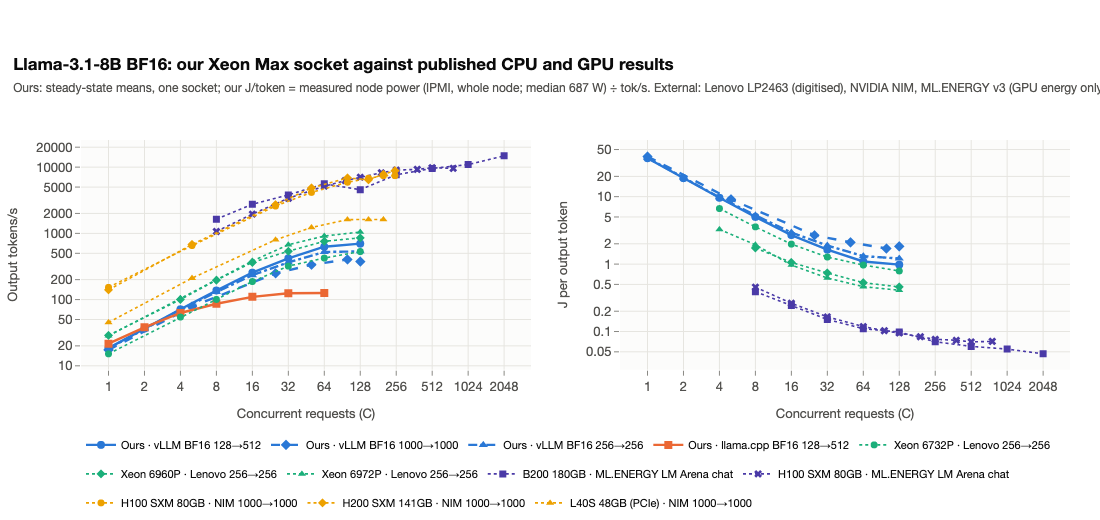

In [11]:
def series_from_ours(cid, wl, label, dash="solid", pts=points, marker=None):
    g = pts[(pts["configuration_id"] == cid) & (pts["workload"] == wl)]
    st = theme.configuration_style(cid)
    own = g["node_power_w"].notna() & (g["node_power_window_s"] >= external.MIN_POWER_WINDOW_S)
    power = g["node_power_w"].where(own, POWER_W)
    return pd.DataFrame({"label": label, "group": "ours", "origin": "ours", "color": st.color, "marker": marker or st.symbol, "dash": dash,
                         "concurrency": g["concurrency"], "output_tok_s": g["output_tok_s_mean"], "energy": power / g["output_tok_s_mean"]})


SYMBOLS = ["circle", "diamond", "triangle-up", "square", "x"]
ext_rows = []
for (sid, hw, prec, ver, wl), g in refs[refs["precision"] == "bf16"].groupby(["source_id", "hardware", "precision", "engine_version", "workload"], sort=False):
    if sid not in ("lenovo_lp2463", "nvidia_nim", "mlenergy_v3"):
        continue
    short = hw.replace("NVIDIA ", "").replace("Intel ", "")
    ext_rows.append(pd.DataFrame({"label": f"{short} · {sid.split('_')[0].replace('nvidia', 'NIM').replace('lenovo', 'Lenovo').replace('mlenergy', 'ML.ENERGY')} {wl}",
                                  "group": sid, "origin": "external", "color": None, "marker": SYMBOLS[len(ext_rows) % len(SYMBOLS)], "dash": "dot",
                                  "concurrency": g["concurrency"], "output_tok_s": g["output_tok_s"], "energy": g["energy_j_per_output_token"]}))
series = pd.concat([series_from_ours("vllm_bf16", "decode", "Ours · vLLM BF16 128→512"),
                    series_from_ours("vllm_bf16", "ext1000", "Ours · vLLM BF16 1000→1000", dash="dash", pts=ext_points, marker="diamond"),
                    series_from_ours("vllm_bf16", "ext256", "Ours · vLLM BF16 256→256", dash="dashdot", pts=ext_points, marker="triangle-up"),
                    series_from_ours("llama_cpp_bf16", "decode", "Ours · llama.cpp BF16 128→512")] + ext_rows, ignore_index=True)
series.loc[series["label"].str.startswith("Ours · llama.cpp"), "energy"] = np.nan  # one estimated energy curve is enough
fig = plots.external_reference_figure(
    series, panels=[("output_tok_s", "Output tokens/s"), ("energy", "J per output token")],
    title="Llama-3.1-8B BF16: our Xeon Max socket against published CPU and GPU results",
    subtitle=f"Ours: steady-state means, one socket; our J/token = measured node power (IPMI, whole node; median {num(POWER_W)} W) ÷ tok/s. "
             "External: Lenovo LP2463 (digitised), NVIDIA NIM, ML.ENERGY v3 (GPU energy only)")
fig.show()
export_figure(fig, "external_reference_bf16", source=NOTEBOOK,
              caption="Output tokens/s and J per output token against concurrency, Llama-3.1-8B BF16: our vLLM and llama.cpp curves (Xeon CPU Max 9480, one socket), "
                      "including our runs at NIM's 1000→1000 and Lenovo's 256→256, next to Lenovo's Xeon 6 vLLM runs, NVIDIA NIM on L40S/H100/H200 and ML.ENERGY on H100/B200; "
                      "our energy uses the measured node power (Slurm IPMI, whole node).")

## 7. Checks and exports

In [12]:
gpu_cl = gpu[~gpu["scenario"].isin(external.PEAK_SCENARIOS)]
claims = [
    Claim("Grade A rows exist, and only for NIM BF16 1000→1000 at the concurrencies we re-measured (C ≤ 100)",
          bool((comp["grade"] == "A").any() and comp.loc[comp["grade"] == "A", "source_id"].eq("nvidia_nim").all() and (comp.loc[comp["grade"] == "A", "concurrency"] <= 100).all()),
          f"{int((comp['grade'] == 'A').sum())} grade A rows"),
    Claim("Every Lenovo row is paired with our run at its exact shape and concurrency", bool((le["shape_distance"] == 0).all() and (le["our_basis"] == "same C").all()), f"{len(le)} rows"),
    Claim("Every GPU delivers more output tok/s than our vLLM at every paired closed-loop or batch-sweep point", bool((gpu_cl["adv_throughput"] > 1).all()), rng(gpu_cl["adv_throughput"], ratio)),
    Claim("Our socket sits between the 32-core and the 72/96-core Xeon 6 in BF16 throughput",
          bool((by["Intel Xeon 6732P"]["adv_throughput"] < 1).all() and (by["Intel Xeon 6972P"]["adv_throughput"] > 1).all() and (by["Intel Xeon 6960P"]["adv_throughput"] > 1).all()),
          f"6732P {rng(by['Intel Xeon 6732P']['adv_throughput'], ratio)}, 6960P {rng(by['Intel Xeon 6960P']['adv_throughput'], ratio)}, 6972P {rng(by['Intel Xeon 6972P']['adv_throughput'], ratio)}"),
    Claim("On the H100 and H200 at C = 100…200 our TTFT is within 1.25× of NIM's in either direction (BF16 1000→1000)", bool(((hi["adv_ttft"] <= 1.25) & (hi["adv_ttft"] >= 1 / 1.25)).all()), rng(hi["adv_ttft"], ratio)),
    Claim("Single-stream decode uses a similar share of the memory roof on our socket and on the GPUs (within 0.6–1.6×)",
          bool(0.6 <= o["roof_share"].median() / gb["roof_share"].median() <= 1.6), f"medians {pct(o['roof_share'].median(), 0, False)} vs {pct(gb['roof_share'].median(), 0, False)}"),
    Claim("Measured node power is nearly constant over load (every point with a ≥ 10-minute window within ±10% of the median)",
          bool(len(POWERS) >= 3 and ((POWERS / POWER_W - 1).abs() <= 0.10).all()), f"{rng(POWERS)} W, median {num(POWER_W)} W, n = {len(POWERS)}"),
    Claim("The idle node was idle (CPU busy share ≤ 1% in every sample) and measured over at least 10 minutes",
          bool(len(IDLE) and (IDLE["cpu_busy_share_max"] <= 0.01).all() and (IDLE["window_s"] >= external.MIN_POWER_WINDOW_S).all()),
          f"busy ≤ {pct(IDLE['cpu_busy_share_max'].max(), 2, False)}, window {num(IDLE['window_s'].min())} s"),
    Claim("Idle node power is below the node power of every loaded point", bool((il["power_above_idle_w"] > 0).all()),
          f"idle {num(IDLE_W)} W, load {rng(il['node_power_w'])} W"),
]
display(claims_table(claims))
export_table(comp, "external_reference_comparison")
export_table(bw, "external_decode_bandwidth")
export_table(pd.DataFrame(KEYS), "external_key_numbers")
display(table(pd.DataFrame(KEYS)[["key", "text", "description"]].rename(columns={"key": "Key", "text": "Value", "description": "Description"}), align="left",
              caption=f"External key numbers ({len(KEYS)}; exported to external_key_numbers.csv)"))

Holds,Statement,Evidence (computed)
✓,"Grade A rows exist, and only for NIM BF16 1000→1000 at the concurrencies we re-measured (C ≤ 100)",15 grade A rows
✓,Every Lenovo row is paired with our run at its exact shape and concurrency,21 rows
✓,Every GPU delivers more output tok/s than our vLLM at every paired closed-loop or batch-sweep point,1.08×–23.5×
✓,Our socket sits between the 32-core and the 72/96-core Xeon 6 in BF16 throughput,"6732P 0.77×–0.99×, 6960P 1.43×–1.60×, 6972P 1.49×–1.96×"
✓,On the H100 and H200 at C = 100…200 our TTFT is within 1.25× of NIM's in either direction (BF16 1000→1000),0.89×–1.22×
✓,Single-stream decode uses a similar share of the memory roof on our socket and on the GPUs (within 0.6–1.6×),medians 59% vs 69%
✓,Measured node power is nearly constant over load (every point with a ≥ 10-minute window within ±10% of the median),"647–712 W, median 687 W, n = 7"
✓,The idle node was idle (CPU busy share ≤ 1% in every sample) and measured over at least 10 minutes,"busy ≤ 0.17%, window 1,080 s"
✓,Idle node power is below the node power of every loaded point,"idle 398 W, load 647–712 W"


Key,Value,Description
ext_cpu_bf16_xeon6_96c_over_ours,1.49×–1.96×,"Xeon 6972P (96 cores, vLLM BF16, 256→256) output tok/s ÷ ours (vLLM BF16, 256→256, external-shapes), same C = 1…128 (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_72c_over_ours,1.43×–1.60×,"Xeon 6960P (72 cores) output tok/s ÷ ours, same shape 256→256 and C (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_32c_over_ours,0.77×–0.99×,"Xeon 6732P (32 cores) output tok/s ÷ ours, same shape 256→256 and C (Lenovo LP2463, digitised)"
ext_cpu_bf16_xeon6_ttft_ours_over_ext,0.10×–0.96×,"Our TTFT ÷ Lenovo's Xeon 6 TTFT, same shape 256→256 and C = 8…128 (< 1: ours lower)"
ext_mlperf_cpu_offline_total_per_socket_over_ours,1.77×–2.81×,"MLPerf v5.1 CPU-only (2× Xeon 6980P W4A8; 2× Xeon 6787P W8A8) Offline total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128"
ext_mlperf_cpu_server_total_per_socket_over_ours,0.63×–1.03×,"MLPerf v5.1 CPU-only Server total tok/s per socket ÷ our vLLM W8A8 peak total tok/s, 4096→128"
ext_gpu_bf16_h100_over_ours,8.37×–19.8×,"NIM H100 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000 (external-shapes), same C ≤ 100, our C = 128 above"
ext_gpu_bf16_h200_over_ours,8.04×–23.5×,"NIM H200 SXM BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000, same C ≤ 100, our C = 128 above"
ext_gpu_bf16_l40s_over_ours,2.60×–4.31×,"NIM L40S BF16 1000→1000 output tok/s ÷ our vLLM BF16 1000→1000, same C ≤ 100, our C = 128 above"
ext_gpu_bf16_tpot_c1_over_ours,2.57×–8.69×,"Our C=1 median TPOT ÷ NIM mean ITL (L40S, H100, H200; BF16 1000→1000, same shape)"


## Conclusions

- **Other CPUs (measured by others, compared by us at their shape).** In BF16 with vLLM at Lenovo's exact shape (256→256)
  and concurrencies, our 55-core Xeon Max socket sits between the current Xeon 6 servers. The 72- and 96-core parts deliver
  1.4–2.0× our output tokens/s, and the 32-core part 0.8–1.0× (section 2.1). Our TTFT is lower than theirs from C = 8 upward
  with the same prompts. We are **not far off** the CPU state of the art; the remaining gap is of the order of core count and
  memory generation, and it widens at C = 128, where our socket stops scaling and theirs do not.
- **GPUs (grade A against NIM 1000→1000).** At the same shape and concurrency, a single data-center GPU delivers several
  times to an order of magnitude more output tokens/s than our socket. That is about 8–15× for the H100 and 8–17× for the H200,
  and 2.6–4× for the L40S at C ≤ 100, and more against our C = 128 plateau. Single-stream decode tracks the memory-bandwidth ratio, and
  the GPUs use their bandwidth about as efficiently as we use ours (section 5), so the C = 1 gap is mostly hardware.
- **Where a CPU is closest.** TTFT under load: the GPUs prefill 9–30× faster at C ≤ 5, but at C ≥ 100 our TTFT is within
  about 1.2× of the H100's and H200's, at the same 1000-token prompts.
- **Energy (now measured, at the node).** The node draws about 650–710 W whatever the load, so energy per token falls as
  throughput rises. That is 9–21× more energy per token than ML.ENERGY's GPU-only figures and 1.4–3× more than Lenovo's Xeon
  6 servers. Lenovo's numbers imply about half our node power, so part of that gap may be the power boundary.
- **Idle against load (section 4.1).** The idle node already draws about 400 W, so serving adds only 250–310 W (38–44% of the
  loaded node). Counting only that increment (an additional estimate, a lower bound of the server's energy), the GPU lead
  shrinks to about 4–6× (H100) and 4–9× (B200), and the 96-core Xeon 6 leads by only about 1.1–1.3×.
- **Next steps.**
  1. Separate the server socket from the rest of the node. The idle baseline (section 4.1) bounds the server's energy from
     both sides; RAPL, if access is granted, would split the socket from memory and platform.
  2. Optionally, run llama.cpp and vLLM W8A8 at the two external shapes. Only BF16 vLLM was re-measured, and FP8 against W8A8
     stays grade B in any case.

## Limitations

- **Exact matches are few, and the statistics differ.** Only NIM's BF16 1000→1000 sweep at C ≤ 100 is grade A. Lenovo's rows
  match in shape and C but name Llama 3 8B. The other rows still mix the hardware gap with a workload difference. NIM reports
  mean TTFT and ITL, ours are medians, and Lenovo's metric definitions are not stated.
- **Digitised values.** Lenovo's values are digitised from its figures (about ±2%). Its text quotes efficiencies 10–20% lower
  than its Figure 2 shows, and its socket count and power boundary are not stated.
- **Mismatched energy boundaries.** ML.ENERGY counts GPU energy only, and ours counts the whole node: both sockets, memory,
  platform and the client. The idle baseline is one 20-minute run on one node (cresco8-hbm01, the node of the 1000→1000
  runs, not of the 256→256 runs), and the incremental estimate assumes the idle part stays constant under load. The IPMI counter updates every 60 s, so only points measured for at least 10 minutes use their own
  power, and the rest use the median. The primary-campaign points were not measured and use that median.
- **MLPerf comparison.** The MLPerf rows use other quantisation (W4A8, FP8) and a dataset with no counterpart among our shapes.
  They are compared on total tokens/s for context only.
- **Vendor sources.** Vendor documents report best-case configurations of their own products.